# Analisis sentimen ulasan Superapp Polri

Notebook ini dijalankan secara lokal dari environment proyek. Jalankan scraper terlebih dahulu, atau letakkan CSV hasil scraping di folder `data/`.

In [1]:
from pathlib import Path

# Berkas default yang dibuat oleh scraping.py
csv_path = Path("../data/ulasan_superapp_polri.csv")
if not csv_path.exists():
    # Fallback bila notebook dijalankan dari root repository
    csv_path = Path("data/ulasan_superapp_polri.csv")

if not csv_path.exists():
    raise FileNotFoundError(
        f"CSV tidak ditemukan: {csv_path}. Jalankan scraper dari root repository atau ubah csv_path ke lokasi CSV-mu."
    )

print(f"Membaca: {csv_path.resolve()}")

Membaca: E:\CODING\analisis-sentimen-superapp-polri\data\ulasan_superapp_polri.csv


## Import library analisis

Jika ada modul yang belum ditemukan, pasang `requirements-analysis.txt` ke environment kernel notebook.

In [2]:
import pandas as pd
import numpy as np
import re

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay

3. Baca CSV

In [3]:
df = pd.read_csv(csv_path, sep=";")
df.head()

,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,ce213f41-f763-4f93-ae5a-287efbaf246b,saputra yudha,https://play-lh.googleusercontent.com/a/ACg8oc...,aplikasi sampah,1,0,2.2.8,2026-10-18 14:13:08,NaN,NaN,2.2.8
1,7e966525-8965-49a7-ab90-74c9ec6034be,DONATBER AMBENNU,https://play-lh.googleusercontent.com/a/ACg8oc...,baik,5,0,2.2.8,2026-10-18 12:31:56,NaN,NaN,2.2.8
2,2fbd0dbd-caf6-45bb-aa98-a21c28298490,Iwa Kartiwa,https://play-lh.googleusercontent.com/a/ACg8oc...,praktis,5,0,2.2.8,2026-10-18 12:26:26,NaN,NaN,2.2.8
3,ba8b36da-91ac-4680-b596-72d6a15ca375,Edi Kubal,https://play-lh.googleusercontent.com/a-/ALV-U...,gaga,5,0,2.2.8,2026-10-18 11:09:38,NaN,NaN,2.2.8
4,630889d9-d3a6-4842-8134-876a11d9aea1,Iskandar Kurnia,https://play-lh.googleusercontent.com/a-/ALV-U...,good job,5,0,2.2.8,2026-10-18 10:39:15,NaN,NaN,2.2.8


In [4]:
print("Jumlah data:", len(df))
print("Kolom:", df.columns.tolist())

Jumlah data: 1000
Kolom: ['reviewId', 'userName', 'userImage', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'appVersion']


4. Pilih Kolom yang Diperlukan

In [5]:
df = df[['content', 'score']]

df.head()

,content,score
0,aplikasi sampah,1
1,baik,5
2,praktis,5
3,gaga,5
4,good job,5


5. Cek Data yang Kosong

In [6]:
df.isnull().sum()

content    0
score      0
dtype: int64

In [7]:
df = df.dropna(subset=["content", "score"]).copy()
df["content"] = df["content"].astype(str)
df["score"] = pd.to_numeric(df["score"], errors="coerce")
df = df.dropna(subset=["score"]).copy()

print("Jumlah data setelah nilai kosong dibuang:", len(df))

Jumlah data setelah nilai kosong dibuang: 1000


6. Hapus Data Duplikat

In [8]:
df = df.drop_duplicates(subset=['content'])

print("Jumlah data setelah duplikat dihapus:", len(df))

Jumlah data setelah duplikat dihapus: 752


7. Buat Label Sentimen

In [9]:
def label_sentiment(score):
    if score >= 4:
        return 'positif'
    elif score == 3:
        return 'netral'
    else:
        return 'negatif'

df['sentiment'] = df['score'].apply(label_sentiment)

df.head()

,content,score,sentiment
0,aplikasi sampah,1,negatif
1,baik,5,positif
2,praktis,5,positif
3,gaga,5,positif
4,good job,5,positif


In [10]:
df['sentiment'].value_counts()

sentiment
positif    403
negatif    317
netral      32
Name: count, dtype: int64

8. Visualisasi Distribusi Sentimen

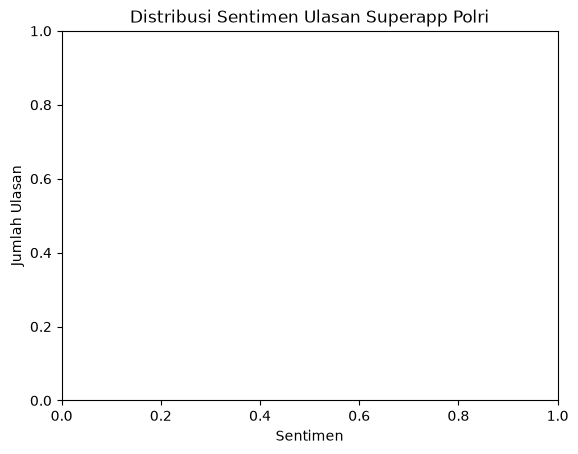

In [11]:
plt.title('Distribusi Sentimen Ulasan Superapp Polri')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Ulasan')
plt.show()

9. Cleaning Text

In [12]:
def clean_text(text):
    text = str(text).lower()

    # Hapus URL, angka, tanda baca, dan karakter khusus
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [13]:
df["clean_text"] = df["content"].apply(clean_text)
df = df[df["clean_text"].str.len() > 0].copy()
df[["content", "clean_text"]].head()

,content,clean_text
0,aplikasi sampah,aplikasi sampah
1,baik,baik
2,praktis,praktis
3,gaga,gaga
4,good job,good job


10. Tentukan X dan Y

In [14]:
X = df['clean_text']
y = df['sentiment']

11. Split Dataset

In [15]:
class_counts = y.value_counts()
if len(class_counts) < 2 or class_counts.min() < 2:
    raise ValueError(
        "Setiap kelas sentimen perlu memiliki minimal 2 ulasan untuk split stratified. "
        f"Jumlah per kelas: {class_counts.to_dict()}"
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [16]:
print("Data training:", len(X_train))
print("Data testing:", len(X_test))

Data training: 596
Data testing: 150


12. TF-IDF

In [17]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

13. Training Model

In [18]:
model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

model.fit(X_train_tfidf, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

14. Prediksi Data Testing

In [19]:
y_pred = model.predict(X_test_tfidf)

15. Lihat Akurasi

In [20]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.78


16. Classification Report

In [21]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     negatif       0.73      0.88      0.79        64
      netral       0.20      0.17      0.18         6
     positif       0.88      0.75      0.81        80

    accuracy                           0.78       150
   macro avg       0.60      0.60      0.60       150
weighted avg       0.79      0.78      0.78       150



## Confusion matrix

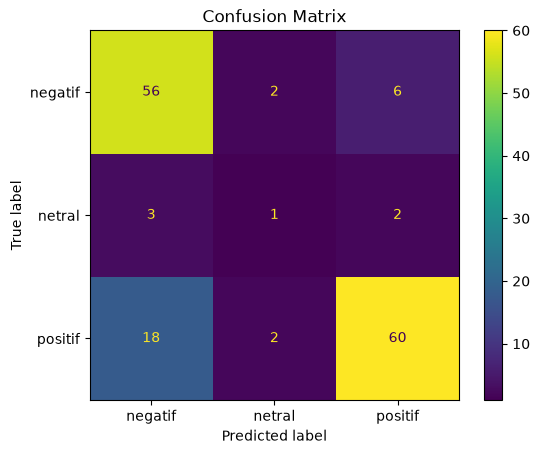

In [22]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title('Confusion Matrix')
plt.show()

18. Coba Komentar Sendiri

In [23]:
def predict_sentiment(text):
    cleaned = clean_text(text)

    vector = tfidf.transform([cleaned])

    prediction = model.predict(vector)[0]

    return prediction

In [24]:
predict_sentiment("aplikasinya sangat membantu dan mudah digunakan")

'positif'

In [25]:
predict_sentiment("kecewa banget aplikasi sering error")

'negatif'

In [26]:
predict_sentiment("ya biasa aja sih")

'positif'

In [27]:
df['sentiment'].value_counts()

sentiment
positif    397
negatif    317
netral      32
Name: count, dtype: int64